# UTS Praktikum Visi Komputer: Deteksi Kematangan Buah

## 1. Identitas

| | |
|---|---|
| **Kelompok** | 5 |
| **Tema** | Deteksi Kematangan Buah |
| **Kelas** | Praktikum Visi Komputer B |

| No | Nama | NIM | Tahap pipeline yang dikerjakan |
|---|---|---|---|
| 1 | Rijaluddin Abdul Ghani | 2408107010008 | Pre-processing dan segmentasi |
| 2 | M. Ilham |2408107010043|Kontur dan Klasifikasi Hue |
| 3 | Fathurrahman Pahmiputra|2408107010069 | Dataset dan Groud Truth |
| 4 | Muhammad Shidqi Hanif|2408107010096 | Evaluasi dan Eksperimen |

**Sumber kode**
- Kerangka notebook dan sebagian fungsi (`pisah_blob`, `pilih_tengah`, `diagnosis`, sel tuning) dikembangkan dengan bantuan asisten AI (Claude). Namun untuk evaluasi, analisis, dan interpretasi tentunya tetap perlu pemahaman sendiri.
- Konversi HSV, rentang Hue 0-179, dan pola `inRange` + `bitwise_and` mengacu pada dokumentasi OpenCV "Changing Colorspaces" (fungsi `praproses`, `segmentasi`, `mask_kelas`, `peta_kelas`; konstanta `GESER`).
- Operasi morfologi (`morphologyEx`, `erode`, `dilate`) mengacu pada Gonzalez & Woods (2018) dan dokumentasi OpenCV (fungsi `segmentasi`, `pisah_blob`).
- Pencarian kontur (`cv2.findContours`) memakai algoritma border following dari Suzuki & Abe (1985) (fungsi `deteksi_kontur`, `pisah_kontur`).
- Pembagian data kalibrasi (foto ideal) dan uji (kondisi lain) serta grid search ambang mengikuti praktik umum pemisahan data train/validation/test (Hastie dkk., 2009) (bagian 6.1).
- Pergeseran Hue +10 untuk merah yang melingkar, heuristik `pisah_blob`, dan pemilihan titik tengah dataran (`pilih_tengah`) adalah rancangan kelompok.

**Referensi**
1. OpenCV Documentation, "Changing Colorspaces", https://docs.opencv.org/4.x/df/d9d/tutorial_py_colorspaces.html
2. Suzuki, S. & Abe, K. (1985). Topological structural analysis of digitized binary images by border following. CVGIP 30(1), 32-46.
3. Gonzalez, R. C. & Woods, R. E. (2018). Digital Image Processing, 4th ed. Pearson.
4. Bradski, G. & Kaehler, A. (2008). Learning OpenCV. O'Reilly Media.
5. Hastie, T., Tibshirani, R. & Friedman, J. (2009). The Elements of Statistical Learning, 2nd ed. Springer.

**Ringkasan.** Program mendeteksi tiap buah pada foto, mengelompokkannya menjadi *mentah*, *setengah matang*, dan *matang* berdasarkan rentang Hue, lalu menghitung jumlah per kelas.

**Cara menjalankan.** Letakkan folder `dataset/` (berisi foto dan `ground_truth.csv`), lalu *Restart & Run All*. Semua path-nya bersifat relatif.

## 2. Import dan fungsi bantu

Setiap tahap pipeline ditulis sebagai fungsi: `praproses` -> `segmentasi` -> `deteksi_kontur` -> `pisah_kontur` -> `filter_bentuk` -> `ekstrak_fitur` -> `klasifikasi`.

Semua parameter ada di satu dictionary,  yaitu `CFG_DEFAULT`. Nilai di dalamnya adalah **nilai default** dan tidak pernah diubah. Setiap eksperimen atau tuning membuat salinannya melalui `buat_cfg`.

In [ ]:
import os
import csv
from glob import glob

import cv2
import numpy as np
import matplotlib.pyplot as plt

KELAS = ["mentah", "setengah_matang", "matang"]
WARNA = {"mentah": (0, 180, 0), "setengah_matang": (0, 165, 255), "matang": (0, 0, 255)}  # BGR

# Nama folder
KONDISI_MAP = {"ideal": "ideal", "lampu": "cahaya", "jendela": "cahaya",
               "cahaya": "cahaya", "sudut": "sudut", "sulit": "sulit"}
KONDISI_URUT = ["ideal", "cahaya", "sudut", "sulit"]
KONDISI_KALIBRASI = ["ideal"]

# Hue OpenCV bernilai 0-179. Merah ada di 170-179 dan 0-10, jadi Hue digeser +10 agar menyatu.
GESER = 10

# Nilai default
CFG_DEFAULT = dict(
    # pre-processing
    ruang="hsv",         # ruang warna klasifikasi: "hsv" atau "bgr" (pembanding)
    sisi_max=1000,       # sisi terpanjang setelah resize, soal menyarankan 800-1200 px
    blur_k=5,            # Gaussian 5x5: meredam noise dan tekstur kulit, namun tepi tetap jelas
    eq_v=False,          # equalization channel V (eksperimen)

    # segmentasi
    s_min=50,            # buah berwarna jenuh, latar putih/abu polos bersaturasi rendah
    v_rel=0.85,          # buah lebih gelap dari 85% median V citra
    morph_k=5,           # kernel open/close: buang bintik, tutup lubang akibat pantulan
    min_area=0.004,      # kontur < 0,4% luas citra dianggap noise

    # pemisahan buah berdempetan dan filter bentuk
    pisah_dempet=True,   # pisahkan blob yang berisi beberapa buah
    seed_min=0.05,       # tiap pecahan minimal 5% luas blob
    aspek_max=2.5,       # rasio sisi minAreaRect maksimum (buang garis tepi memanjang)
    ekstent_min=0.5,     # luas kontur / luas minAreaRect minimum (buang bentuk yg tidak padat)

    # klasifikasi
    h_matang=7,          # Hue <= 7 (dan 170-179) -> matang
    h_setengah=12,       # Hue 8-12 -> setengah matang, > 12 -> mentah
    bgr_r=(0.50, 0.75),  # ambang R/(R+G) untuk pembanding BGR
)

# Parameter yang memengaruhi deteksi
DETEKSI_KEYS = ["sisi_max", "blur_k", "eq_v", "s_min", "v_rel", "morph_k",
                "min_area", "pisah_dempet", "seed_min", "aspek_max", "ekstent_min"]

def buat_cfg(base=None, **ubah):
    """Salinan konfigurasi dengan sebagian nilai diganti."""
    cfg = dict(CFG_DEFAULT if base is None else base)
    for k in ubah:
        assert k in CFG_DEFAULT, f"Parameter tidak dikenal: {k}"
    cfg.update(ubah)
    return cfg

In [ ]:
def rgb(x):
    return cv2.cvtColor(x, cv2.COLOR_BGR2RGB)

_CACHE_CITRA = {}

def muat_citra(path, sisi_max=1000):
    """Baca citra lalu resize agar sisi terpanjang = sisi_max. Hasil di-cache."""
    kunci = (path, sisi_max)
    if kunci not in _CACHE_CITRA:
        img = cv2.imread(path)
        assert img is not None, f"Gagal membaca {path}"
        skala = sisi_max / max(img.shape[:2])
        if skala < 1:
            img = cv2.resize(img, None, fx=skala, fy=skala, interpolation=cv2.INTER_AREA)
        _CACHE_CITRA[kunci] = img
    return _CACHE_CITRA[kunci]


def tabel(rows, cols):
    """Cetak list of dict sebagai tabel teks."""
    if not rows:
        print("(kosong)")
        return
    lebar = {c: max(len(c), *(len(str(r[c])) for r in rows)) for c in cols}
    print(" | ".join(c.ljust(lebar[c]) for c in cols))
    print("-+-".join("-" * lebar[c] for c in cols))
    for r in rows:
        print(" | ".join(str(r[c]).ljust(lebar[c]) for c in cols))

In [ ]:
# Tahap 1: praproses dan segmentasi

def praproses(img, cfg):
    """Blur Gaussian -> HSV -> (opsional equalization V)."""
    bgr = cv2.GaussianBlur(img, (cfg["blur_k"],) * 2, 0) if cfg["blur_k"] > 1 else img.copy()
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    if cfg["eq_v"]:
        hsv[..., 2] = cv2.equalizeHist(np.ascontiguousarray(hsv[..., 2]))
        bgr = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
    return bgr, hsv

def segmentasi(hsv, cfg):
    """Buah = jenuh (S >= s_min) dan lebih gelap dari latar (V < v_rel x median V)."""
    v_ref = int(np.median(hsv[..., 2]))
    mask = cv2.inRange(hsv, (0, cfg["s_min"], 0), (179, 255, int(cfg["v_rel"] * v_ref)))
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (cfg["morph_k"],) * 2)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    return cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

In [ ]:
# Tahap 2: kontur, pemisahan buah berdempetan, filter bentuk

def deteksi_kontur(mask, cfg):
    """Kontur luar tiap blob, buang yang terlalu kecil."""
    kontur, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return [c for c in kontur if cv2.contourArea(c) >= cfg["min_area"] * mask.size]


def pisah_blob(blob, seed_min):
    """Pisahkan blob berisi beberapa buah dengan erosi bertahap."""
    kernel = np.ones((3, 3), np.uint8)
    luas = cv2.countNonZero(blob)
    erosi, terbaik, iter_terbaik = blob.copy(), None, 0
    for it in range(1, 80):
        erosi = cv2.erode(erosi, kernel)
        kontur, _ = cv2.findContours(erosi, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        seed = [c for c in kontur if cv2.contourArea(c) >= seed_min * luas]
        if not seed:
            break
        if len(seed) >= 2 and (terbaik is None or len(seed) > len(terbaik)):
            terbaik, iter_terbaik = seed, it
    if terbaik is None:
        return [blob]
    hasil = []
    for c in terbaik:
        s = np.zeros_like(blob)
        cv2.drawContours(s, [c], -1, 255, -1)
        s = cv2.dilate(s, kernel, iterations=iter_terbaik + 1)
        hasil.append(cv2.bitwise_and(s, blob))
    return hasil


def pisah_kontur(daftar_kontur, shape, cfg):
    """Pecah kontur yang berisi beberapa buah menjadi satu kontur per buah."""
    hasil = []
    for c in daftar_kontur:
        blob = np.zeros(shape[:2], np.uint8)
        cv2.drawContours(blob, [c], -1, 255, -1)
        bagian = pisah_blob(blob, cfg["seed_min"]) if cfg["pisah_dempet"] else [blob]
        for b in bagian:
            kontur, _ = cv2.findContours(b, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            if kontur:
                hasil.append(max(kontur, key=cv2.contourArea))
    return hasil


def filter_bentuk(daftar_kontur, shape, cfg):
    """Buang noise: terlalu kecil, terlalu memanjang, atau bukan bentuk padat."""
    H, W = shape[:2]
    hasil = []
    for c in daftar_kontur:
        (_, _), (w, h), _ = cv2.minAreaRect(c)
        luas = cv2.contourArea(c)
        terlalu_kecil = luas < cfg["min_area"] * H * W
        terlalu_panjang = max(w, h) / max(min(w, h), 1) > cfg["aspek_max"]
        tidak_padat = luas / max(w * h, 1) < cfg["ekstent_min"]
        if not (terlalu_kecil or terlalu_panjang or tidak_padat):
            hasil.append(c)
    return hasil

In [ ]:
# Tahap 3: fitur per buah dan klasifikasi

def mask_kontur(shape, kontur):
    """Mask terisi satu kontur, agar piksel tepi tidak ikut."""
    m = np.zeros(shape[:2], np.uint8)
    cv2.drawContours(m, [kontur], -1, 255, -1)
    dalam = cv2.erode(m, np.ones((5, 5), np.uint8))
    return dalam if cv2.countNonZero(dalam) else m


def ekstrak_fitur(bgr, hsv, kontur, cfg):
    """Fitur warna satu buah, dihitung dari piksel jenuh di dalam kontur."""
    m = mask_kontur(hsv.shape, kontur)
    jenuh = cv2.inRange(hsv, (0, cfg["s_min"], 0), (179, 255, 255))
    piksel = cv2.bitwise_and(m, jenuh)
    if cv2.countNonZero(piksel) == 0:
        piksel = m
    idx = piksel > 0
    hue = (hsv[..., 0][idx].astype(int) + GESER) % 180
    b, g, r = bgr[idx].astype(float).mean(axis=0)
    return dict(
        kontur=kontur,
        bbox=cv2.boundingRect(kontur),
        luas=cv2.contourArea(kontur),
        h_med=float(np.median(hue)),                      # median Hue (sudah digeser)
        h_hist=np.bincount(hue, minlength=180),           # sebaran Hue piksel buah
        rasio_rg=float(r / (r + g + 1e-6)),               # fitur pembanding ruang BGR
        hsv_med=tuple(int(np.median(hsv[..., i][m > 0])) for i in range(3)),
    )

def klasifikasi(fitur, cfg):
    """Tentukan kelas satu buah dari median Hue (HSV) atau rasio R/(R+G) (BGR)."""
    if cfg["ruang"] == "bgr":
        t1, t2 = cfg["bgr_r"]
        q = fitur["rasio_rg"]
        return "mentah" if q < t1 else ("setengah_matang" if q < t2 else "matang")

    h = fitur["h_med"]
    if h <= cfg["h_matang"] + GESER:
        return "matang"
    return "setengah_matang" if h <= cfg["h_setengah"] + GESER else "mentah"


def deteksi_buah(img, cfg):
    """Praproses -> segmentasi -> kontur -> pisah dempet -> filter -> fitur."""
    bgr, hsv = praproses(img, cfg)
    mask = segmentasi(hsv, cfg)
    kontur = deteksi_kontur(mask, cfg)
    kontur = pisah_kontur(kontur, mask.shape, cfg)
    kontur = filter_bentuk(kontur, mask.shape, cfg)
    buah = [ekstrak_fitur(bgr, hsv, c, cfg) for c in kontur]
    return dict(bgr=bgr, hsv=hsv, mask=mask, buah=buah)


def klasifikasi_buah(det, cfg):
    """Beri kelas pada tiap buah dan hitung jumlah per kelas."""
    hitung = dict.fromkeys(KELAS, 0)
    hasil = []
    for b in det["buah"]:
        kelas = klasifikasi(b, cfg)
        hitung[kelas] += 1
        hasil.append({**b, "kelas": kelas})
    return {**det, "hasil": hasil, "hitung": hitung, "total": len(hasil)}


def jalankan_pipeline(img, cfg):
    return klasifikasi_buah(deteksi_buah(img, cfg), cfg)


_CACHE_FITUR = {}


def fitur_buah(path, cfg):
    """Fitur buah satu foto. Di-cache menurut parameter deteksi, jadi tuning ambang Hue cepat."""
    kunci = (path,) + tuple(cfg[k] for k in DETEKSI_KEYS)
    if kunci not in _CACHE_FITUR:
        img = muat_citra(path, cfg["sisi_max"])
        buah = deteksi_buah(img, cfg)["buah"]
        _CACHE_FITUR[kunci] = [{k: v for k, v in b.items() if k != "kontur"} for b in buah]
    return _CACHE_FITUR[kunci]

In [ ]:
# Visualisasi

def gambar_hasil(img, p, detail=False):
    """Bounding box dan label kelas per buah"""
    out = img.copy()
    for b in p["hasil"]:
        x, y, w, h = b["bbox"]
        warna = WARNA[b["kelas"]]
        cv2.rectangle(out, (x, y), (x + w, y + h), warna, 3)
        label = "H%d S%d V%d" % b["hsv_med"] if detail else b["kelas"]
        cv2.putText(out, label, (x, max(50, y - 8)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, warna, 2)
    t = p["hitung"]
    teks = f"Total {p['total']} | Mentah {t['mentah']} | Setengah {t['setengah_matang']} | Matang {t['matang']}"
    cv2.rectangle(out, (0, 0), (out.shape[1], 34), (255, 255, 255), -1)
    cv2.putText(out, teks, (10, 24), cv2.FONT_HERSHEY_SIMPLEX, 0.65, (0, 0, 0), 2)
    return out


def mask_kelas(hsv, cfg):
    """Mask tiap kelas dari rentang Hue (inRange). Merah memakai dua rentang karena Hue melingkar."""
    s, m, st = cfg["s_min"], cfg["h_matang"], cfg["h_setengah"]

    def rentang(lo, hi):
        return cv2.inRange(hsv, (lo, s, 0), (hi, 255, 255))

    return {"mentah": rentang(st + 1, 85),
            "setengah_matang": rentang(m + 1, st),
            "matang": cv2.bitwise_or(rentang(0, m), rentang(170, 179))}


def peta_kelas(hsv, mask_buah, cfg):
    """Warnai piksel buah menurut rentang Hue-nya (mask kelas AND mask buah)."""
    peta = np.full(hsv.shape, 255, np.uint8)
    for kelas, m in mask_kelas(hsv, cfg).items():
        peta[cv2.bitwise_and(m, mask_buah) > 0] = WARNA[kelas]
    return peta

In [ ]:
# Evaluasi

def format_hitung(total, h):
    return f"{total} ({h['mentah']}/{h['setengah_matang']}/{h['matang']})"

def evaluasi(rows, cfg):
    """Jalankan pipeline ke tiap foto lalu bandingkan jumlah per kelas dengan ground truth."""
    hasil = []
    for r in rows:
        buah = fitur_buah(r["path"], cfg)
        pk = dict.fromkeys(KELAS, 0)
        for b in buah:
            pk[klasifikasi(b, cfg)] += 1
        gk = {k: r[k] for k in KELAS}
        err_kelas = sum(abs(pk[k] - gk[k]) for k in KELAS)
        hasil.append(dict(
            file=r["file"], kondisi=r["kondisi"], path=r["path"],
            total_gt=r["total"], total_pred=len(buah), gk=gk, pk=pk,
            gt=format_hitung(r["total"], gk), pred=format_hitung(len(buah), pk),
            err_total=abs(len(buah) - r["total"]), err_kls=err_kelas,
            benar_total=int(len(buah) == r["total"]), benar_kelas=int(err_kelas == 0)))
    return hasil


def hitung_skor(hasil):
    """Ringkasan metrik untuk sekumpulan hasil."""
    if not hasil:
        return dict(n=0, acc_total=np.nan, acc_kelas=np.nan, MAE_total=np.nan, MAE_kelas=np.nan)
    return dict(
        n=len(hasil),
        acc_total=100 * np.mean([h["benar_total"] for h in hasil]),   # jumlah total buah tepat
        acc_kelas=100 * np.mean([h["benar_kelas"] for h in hasil]),   # jumlah semua kelas tepat
        MAE_total=np.mean([h["err_total"] for h in hasil]),
        MAE_kelas=np.mean([h["err_kls"] for h in hasil]) / 3)


def kondisi_ada(hasil):
    ada = {h["kondisi"] for h in hasil}
    return [k for k in KONDISI_URUT if k in ada] + sorted(ada - set(KONDISI_URUT))


def tabel_kondisi(hasil):
    """Akurasi per kondisi dan keseluruhan."""
    baris = []
    for k in kondisi_ada(hasil) + ["SEMUA"]:
        s = hitung_skor([h for h in hasil if k == "SEMUA" or h["kondisi"] == k])
        baris.append(dict(kondisi=k, n=s["n"], acc_total=f"{s['acc_total']:.1f}%",
                          acc_semua_kelas=f"{s['acc_kelas']:.1f}%",
                          MAE_total=f"{s['MAE_total']:.2f}", MAE_kelas=f"{s['MAE_kelas']:.2f}"))
    return baris


def metrik_kelas(hasil):
    """Precision / recall per kelas berbasis jumlah (TP = min(pred, GT) per foto)"""
    baris = []
    for k in KELAS:
        tp = sum(min(h["pk"][k], h["gk"][k]) for h in hasil)
        P = sum(h["pk"][k] for h in hasil)
        G = sum(h["gk"][k] for h in hasil)
        baris.append(dict(kelas=k, GT=G, pred=P,
                          precision=f"{100 * tp / max(P, 1):.1f}%",
                          recall=f"{100 * tp / max(G, 1):.1f}%",
                          MAE=f"{np.mean([abs(h['pk'][k] - h['gk'][k]) for h in hasil]):.2f}"))
    return baris

## 3. Memuat dataset

Dataset difoto sendiri dengan kamera HP. Bagian ini memuat semua foto dan `ground_truth.csv`, memeriksa konsistensinya (jumlah per kelas harus sama dengan total), memastikan metadata EXIF masih ada, lalu menampilkan satu contoh per kondisi.


Mounted at /content/drive
Total foto: 20 | tanpa EXIF: -
file           | kondisi | total | mentah | setengah_matang | matang
---------------+---------+-------+--------+-----------------+-------
ideal_02.jpg   | ideal   | 7     | 1      | 3               | 3     
ideal_03.jpg   | ideal   | 6     | 1      | 2               | 3     
ideal_07.jpg   | ideal   | 8     | 1      | 3               | 4     
ideal_01.jpg   | ideal   | 8     | 1      | 3               | 4     
ideal_04.jpg   | ideal   | 5     | 1      | 2               | 2     
ideal_05.jpg   | ideal   | 4     | 1      | 2               | 1     
ideal_06.jpg   | ideal   | 3     | 1      | 1               | 1     
ideal_08.jpg   | ideal   | 6     | 1      | 3               | 2     
lampu_01.jpg   | cahaya  | 4     | 0      | 2               | 2     
lampu_04.jpg   | cahaya  | 4     | 0      | 2               | 2     
lampu_03.jpg   | cahaya  | 2     | 0      | 1               | 1     
lampu_02.jpg   | cahaya  | 3     | 0      | 2 

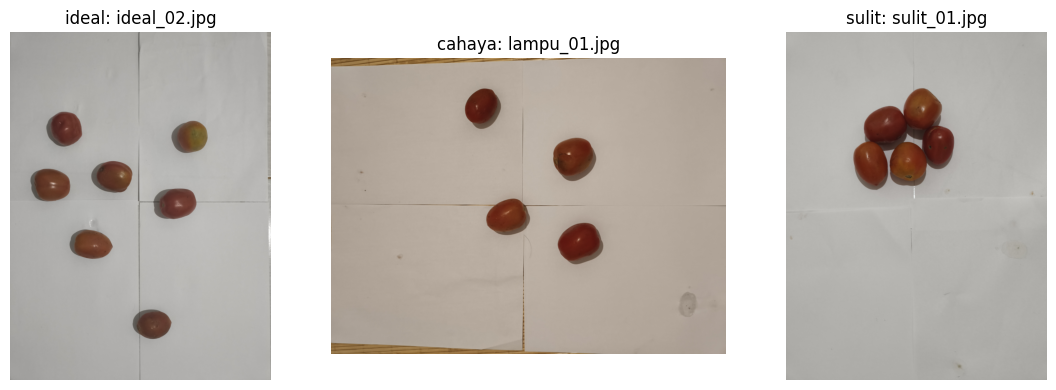

In [ ]:
def cari_dataset():
    """Dataset dicari di ./dataset (path relatif); jika tidak ada, di Google Drive (Colab)."""
    if os.path.exists(os.path.join("dataset", "ground_truth.csv")):
        return "dataset"
    try:
        from google.colab import drive
        if not os.path.isdir("/content/drive/MyDrive"):
            drive.mount("/content/drive")
        folder_drive = "/content/drive/MyDrive/Dataset_Tomat"
        ditemukan = glob(os.path.join(folder_drive, "**", "ground_truth.csv"), recursive=True)
        if ditemukan:
            return os.path.dirname(ditemukan[0])
        if os.path.isdir(folder_drive):
            print("Isi", folder_drive, "->", sorted(os.listdir(folder_drive)))
    except ImportError:
        pass
    raise FileNotFoundError("ground_truth.csv tidak ditemukan di ./dataset maupun /content/drive/MyDrive/Dataset_Tomat.")


def inventaris(folder):
    """Daftar semua foto beserta ukuran asli dan status EXIF."""
    data = []
    for p in sorted(glob(os.path.join(folder, "**", "*.*"), recursive=True)):
        if not p.lower().endswith((".jpg", ".jpeg", ".png")):
            continue
        img = cv2.imread(p)
        if img is None:
            continue
        with open(p, "rb") as f:
            exif = b"Exif" in f.read(65536)
        data.append(dict(file=os.path.basename(p), folder=os.path.basename(os.path.dirname(p)), path=p,
                         resolusi=f"{img.shape[1]}x{img.shape[0]}", exif="ada" if exif else "TIDAK ADA"))
    return data


def tentukan_kondisi(nama, path, kolom):
    """Kondisi dari kolom CSV, nama folder, atau awalan nama file (berurutan)."""
    for kandidat in (kolom, os.path.basename(os.path.dirname(path)), nama.split("_")[0]):
        kondisi = KONDISI_MAP.get((kandidat or "").strip().lower())
        if kondisi:
            return kondisi
    return "lain"


def muat_ground_truth(csv_path, index):
    """Baca ground_truth.csv; setiap baris dihubungkan ke file fotonya."""
    with open(csv_path, encoding="utf-8-sig") as f:
        isi = f.read().splitlines()
    pemisah = ";" if ";" in isi[0] else ","
    rows, hilang = [], []
    for r in csv.DictReader(isi, delimiter=pemisah):
        r = {k.strip().replace("\\", "").lower(): (v or "").strip() for k, v in r.items() if k}
        nama = r.get("file") or r.get("nama_file")
        path = index.get(nama.lower())
        if path is None:
            hilang.append(nama)
            continue
        d = dict(file=nama, path=path, kondisi=tentukan_kondisi(nama, path, r.get("kondisi")))
        d.update({k: int(r[k]) for k in ["total"] + KELAS})
        assert d["total"] == sum(d[k] for k in KELAS), f"Ground truth tidak konsisten: {nama}"
        rows.append(d)
    assert not hilang, f"Foto tidak ditemukan untuk baris GT: {hilang}"
    return rows


DATASET_DIR = cari_dataset()
CSV_PATH = os.path.join(DATASET_DIR, "ground_truth.csv")
OUTPUT_DIR = "output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

INV = inventaris(DATASET_DIR)
INDEX = {}
for i in INV:
    if i["file"].lower() in INDEX:
        print("nama file ganda ->", i["file"])
    INDEX[i["file"].lower()] = i["path"]

tanpa_exif = [i["file"] for i in INV if i["exif"] != "ada"]
print(f"Total foto: {len(INV)} | tanpa EXIF: {tanpa_exif or '-'}")

DATA = muat_ground_truth(CSV_PATH, INDEX)
KOND = kondisi_ada(DATA)
KAL_ROWS = [r for r in DATA if r["kondisi"] in KONDISI_KALIBRASI] or DATA
UJI_ROWS = [r for r in DATA if r["kondisi"] not in KONDISI_KALIBRASI]

tabel(DATA, ["file", "kondisi", "total", "mentah", "setengah_matang", "matang"])
print()
tabel([dict(kondisi=k, foto=sum(r["kondisi"] == k for r in DATA), buah=sum(r["total"] for r in DATA if r["kondisi"] == k))
       for k in KOND], ["kondisi", "foto", "buah"])
print(f"Kalibrasi: {len(KAL_ROWS)} foto ({', '.join(KONDISI_KALIBRASI)}) | Uji: {len(UJI_ROWS)} foto (kondisi lain)")

fig, ax = plt.subplots(1, len(KOND), figsize=(4 * len(KOND), 4), squeeze=False)
for a, k in zip(ax[0], KOND):
    r = next(x for x in DATA if x["kondisi"] == k)
    a.imshow(rgb(muat_citra(r["path"]))); a.set_title(f"{k}: {r['file']}"); a.axis("off")
plt.tight_layout(); plt.show()

## 4. Pipeline

Urutan: **asli -> blur -> HSV (Hue, Saturation) -> mask buah -> kontur -> kelas per piksel -> hasil akhir.**

Alasan metode dan parameter (nilai default):

| Tahap | Metode dan parameter | Alasan teknis |
|---|---|---|
| Resize | sisi terpanjang 1000 px | Dalam rentang 800-1200 px dari soal. Luas diukur relatif, jadi hasil tidak bergantung resolusi asli. |
| Blur | Gaussian 5x5 | Meredam noise sensor dan tekstur kulit, tepi buah tetap jelas. |
| Ruang warna | HSV | Hue memisahkan warna dari intensitas cahaya; proses pematangan adalah pergeseran warna (hijau, oranye, merah). |
| Mask buah | `inRange`: S >= 50 dan V < 0,85 x median V | Latar putih/abu polos bersaturasi rendah, buah jenuh dan lebih gelap. Batas V relatif terhadap median citra, jadi ikut menyesuaikan terang-gelapnya cahaya. |
| Morfologi | open + close, elips 5x5 | Open membuang bintik, close menutup lubang akibat pantulan cahaya. |
| Kontur | `findContours`, luas minimal 0,4% citra | Kontur yang lebih kecil hampir pasti noise. |
| Pisah dempet | erosi bertahap, seed minimal 5% luas blob | Buah yang menempel menjadi satu kontur; erosi memecahnya, buah tunggal tidak pernah terpecah. |
| Filter bentuk | rasio sisi <= 2,5 dan ekstent >= 0,5 | Membuang garis tepi kertas/meja. Buah relatif bulat dan padat. |
| Fitur | median Hue piksel jenuh di dalam kontur (dierosi 5x5) | Median tahan terhadap pantulan dan bercak. Hue digeser +10 agar merah (170-179 dan 0-10) menyatu. |
| Klasifikasi | ambang Hue: matang <= 7, setengah matang 8-12, mentah > 12 | Nilai awal dari pengamatan tomat. Ditinjau dengan histogram Hue (4.2) dan di-tuning di Bagian 6. |

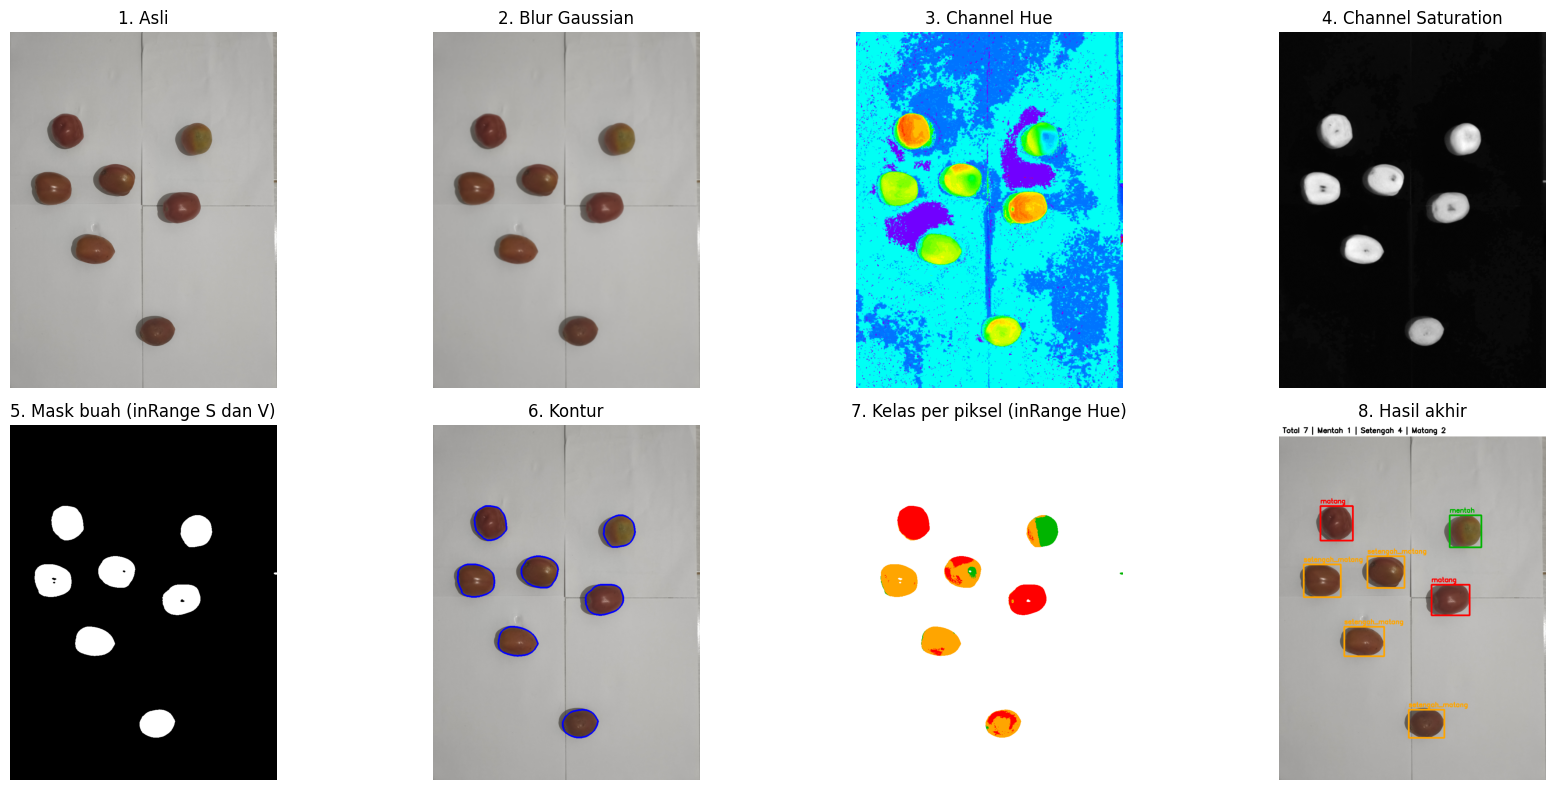

Foto : ideal_02.jpg
GT   : 7 (1/3/3)
Pred : 7 (1/4/2)


In [ ]:
r = next((x for x in DATA if x["kondisi"] == "ideal"), DATA[0])
cfg = CFG_DEFAULT
img = muat_citra(r["path"], cfg["sisi_max"])
p = jalankan_pipeline(img, cfg)

kontur_img = img.copy()
cv2.drawContours(kontur_img, [b["kontur"] for b in p["hasil"]], -1, (255, 0, 0), 3)

langkah = [
    ("1. Asli", rgb(img), None),
    ("2. Blur Gaussian", rgb(p["bgr"]), None),
    ("3. Channel Hue", p["hsv"][..., 0], "hsv"),
    ("4. Channel Saturation", p["hsv"][..., 1], "gray"),
    ("5. Mask buah (inRange S dan V)", p["mask"], "gray"),
    ("6. Kontur", rgb(kontur_img), None),
    ("7. Kelas per piksel (inRange Hue)", rgb(peta_kelas(p["hsv"], p["mask"], cfg)), None),
    ("8. Hasil akhir", rgb(gambar_hasil(img, p)), None),
]
fig, ax = plt.subplots(2, 4, figsize=(18, 8))
for a, (judul, im, cmap) in zip(ax.ravel(), langkah):
    a.imshow(im, cmap=cmap); a.set_title(judul); a.axis("off")
plt.tight_layout(); plt.show()
print("Foto :", r["file"])
print("GT   :", format_hitung(r["total"], r))
print("Pred :", format_hitung(p["total"], p["hitung"]))

### 4.2 Histogram Hue per kelas (dasar rentang Hue)

Ground truth hanya berisi **jumlah per kelas**, bukan kelas tiap buah. Karena itu label buah dibuat sementara, di setiap foto kalibrasi, buah diurutkan menurut Hue (merah ke hijau) lalu dibagi sesuai jumlah per kelas di ground truth.

mentah           n=  8 | median Hue=  17.0 | p10-p90=16 sampai 18
setengah_matang  n= 19 | median Hue=   9.0 | p10-p90=8 sampai 9
matang           n= 20 | median Hue=   4.0 | p10-p90=3 sampai 8


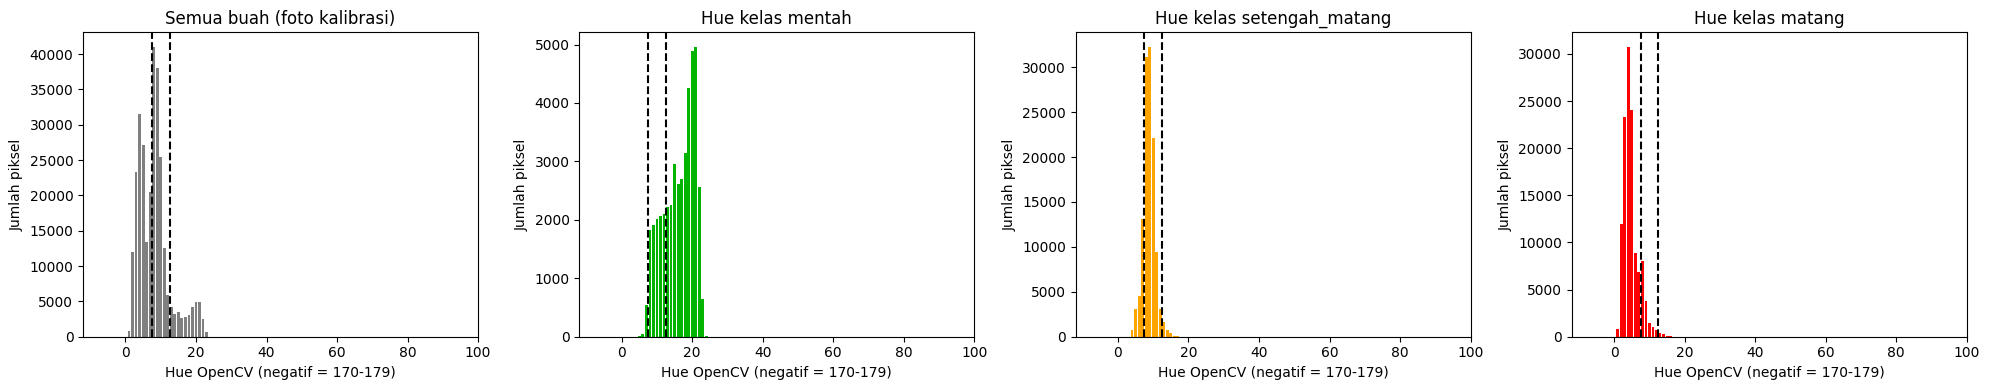

In [ ]:
def label_semu(rows, cfg):
    """Kelompokkan buah per kelas menurut urutan Hue dalam tiap foto dan jumlah GT."""
    kelompok = {k: [] for k in KELAS}
    dilewati = []
    for r in rows:
        buah = sorted(fitur_buah(r["path"], cfg), key=lambda b: b["h_med"])
        if len(buah) != r["total"]:
            dilewati.append(r["file"])
            continue
        a, b = r["matang"], r["matang"] + r["setengah_matang"]
        kelompok["matang"] += buah[:a]
        kelompok["setengah_matang"] += buah[a:b]
        kelompok["mentah"] += buah[b:]
    return kelompok, dilewati


def plot_histogram_hue(kelompok, cfg):
    x = np.arange(180) - GESER
    hist = {k: np.sum([b["h_hist"] for b in kelompok[k]], axis=0) if kelompok[k] else np.zeros(180)
            for k in KELAS}
    batas = [cfg["h_matang"] + 0.5, cfg["h_setengah"] + 0.5]
    fig, ax = plt.subplots(1, 4, figsize=(20, 4))
    ax[0].bar(x, sum(hist.values()), color="gray"); ax[0].set_title("Semua buah (foto kalibrasi)")
    for a, k in zip(ax[1:], KELAS):
        a.bar(x, hist[k], color=[c / 255 for c in WARNA[k][::-1]]); a.set_title(f"Hue kelas {k}")
    for a in ax:
        for bt in batas:
            a.axvline(bt, color="k", ls="--")
        a.set_xlim(-12, 100); a.set_xlabel("Hue OpenCV (negatif = 170-179)"); a.set_ylabel("Jumlah piksel")
    plt.tight_layout(); plt.show()


KELOMPOK, DILEWATI = label_semu(KAL_ROWS, CFG_DEFAULT)
if DILEWATI:
    print("Dilewati (jumlah kontur != GT):", DILEWATI)
for k in KELAS:
    h = np.array([b["h_med"] - GESER for b in KELOMPOK[k]])
    if h.size:
        print(f"{k:16s} n={h.size:3d} | median Hue={np.median(h):6.1f} | p10-p90={np.percentile(h, 10):.0f} sampai {np.percentile(h, 90):.0f}")
plot_histogram_hue(KELOMPOK, CFG_DEFAULT)

## 5. Evaluasi

Pipeline dengan **konfigurasi default** dijalankan ke seluruh dataset dan dibandingkan dengan ground truth. Ambang Hue di sini belum di-tuning, sehingga nanti hasilnya tidak bocor dari data evaluasi.

Metrik:
- `acc_total`: persentase foto dengan **jumlah total buah** tepat (kualitas deteksi).
- `acc_semua_kelas`: persentase foto dengan **jumlah ketiga kelas** tepat (deteksi + klasifikasi, metrik paling ketat).
- `MAE_total` dan `MAE_kelas`: rata-rata selisih absolut jumlah.
- Precision/recall per kelas berbasis jumlah adalah **batas atas**

In [ ]:
HASIL_DEFAULT = evaluasi(DATA, CFG_DEFAULT)

print("Per citra (total (mentah/setengah/matang)):")
tabel(HASIL_DEFAULT, ["file", "kondisi", "gt", "pred", "err_total", "benar_total", "benar_kelas"])
print("\nAkurasi per kondisi:")
tabel(tabel_kondisi(HASIL_DEFAULT), ["kondisi", "n", "acc_total", "acc_semua_kelas", "MAE_total", "MAE_kelas"])
print("\nMetrik per kelas (batas atas):")
tabel(metrik_kelas(HASIL_DEFAULT), ["kelas", "GT", "pred", "precision", "recall", "MAE"])

Per citra (total (mentah/setengah/matang)):
file           | kondisi | gt        | pred      | err_total | benar_total | benar_kelas
---------------+---------+-----------+-----------+-----------+-------------+------------
ideal_02.jpg   | ideal   | 7 (1/3/3) | 7 (1/4/2) | 0         | 1           | 0          
ideal_03.jpg   | ideal   | 6 (1/2/3) | 6 (1/3/2) | 0         | 1           | 0          
ideal_07.jpg   | ideal   | 8 (1/3/4) | 8 (1/4/3) | 0         | 1           | 0          
ideal_01.jpg   | ideal   | 8 (1/3/4) | 8 (1/3/4) | 0         | 1           | 1          
ideal_04.jpg   | ideal   | 5 (1/2/2) | 5 (1/2/2) | 0         | 1           | 1          
ideal_05.jpg   | ideal   | 4 (1/2/1) | 4 (1/2/1) | 0         | 1           | 1          
ideal_06.jpg   | ideal   | 3 (1/1/1) | 3 (1/1/1) | 0         | 1           | 1          
ideal_08.jpg   | ideal   | 6 (1/3/2) | 6 (1/3/2) | 0         | 1           | 1          
lampu_01.jpg   | cahaya  | 4 (0/2/2) | 4 (0/2/2) | 0         | 1  

## 6. Eksperimen pembanding

### 6.1 Tuning parameter dan perbandingan default vs tuned

Data dibagi menurut kondisi: foto **ideal** dipakai untuk kalibrasi, kondisi lainnya untuk **uji**. Pembagian per kondisi dipilih karena foto-foto yang berasal dari buah yang sama saling berkorelasi

Tuning dua tahap, hanya memakai data kalibrasi:
1. **Tahap A (deteksi):** grid `v_rel` x `s_min`, meminimalkan selisih **jumlah total** buah. Tidak memakai label kelas.
2. **Tahap B (klasifikasi):** grid batas Hue `h_matang` x `h_setengah`, meminimalkan selisih jumlah per kelas.

Jika banyak kombinasi sama baiknya, dipilih yang **paling dekat ke pusat dataran** (bukan sudut dataran) supaya tahan terhadap pergeseran kecil. `CFG_DEFAULT` tidak diubah, hasil tuningnya disimpan sebagai `CFG_TUNED`.

**Konfigurasi final = `CFG_TUNED`.** Pilihan ini ditetapkan sebelum melihat data uji, jadi data uji tidak ikut menentukan parameter dan hasilnya tetap murni sebagai uji.

In [ ]:
def pilih_tengah(peta_galat):
    """Dari kombinasi dengan galat minimum, pilih yang paling dekat ke pusat dataran."""
    minimum = min(peta_galat.values())
    terbaik = np.array([k for k, v in peta_galat.items() if v == minimum], dtype=float)
    semua = np.array(list(peta_galat), dtype=float)
    rentang = np.maximum(semua.max(axis=0) - semua.min(axis=0), 1e-9)
    pusat = terbaik.mean(axis=0)
    jarak = np.linalg.norm((terbaik - pusat) / rentang, axis=1)
    return tuple(terbaik[jarak.argmin()]), minimum, len(terbaik)


def galat_kelas(rows, cfg):
    return sum(h["err_kls"] for h in evaluasi(rows, cfg))


def tuning_deteksi(rows, cfg, v_rel=(0.70, 0.75, 0.80, 0.85, 0.90), s_min=(30, 40, 50, 60)):
    """Tahap A: pilih v_rel dan s_min dari galat jumlah total buah."""
    peta = {}
    for v in v_rel:
        for s in s_min:
            hasil = evaluasi(rows, buat_cfg(cfg, v_rel=v, s_min=s))
            peta[(v, s)] = sum(h["err_total"] for h in hasil)
    (v, s), galat, n_sama = pilih_tengah(peta)
    return buat_cfg(cfg, v_rel=round(float(v), 2), s_min=int(s)), galat, n_sama


def tuning_hue(rows, cfg):
    """Tahap B (HSV): pilih batas Hue dari galat jumlah per kelas."""
    peta = {}
    for b_m in range(2, 16):
        for b_s in range(b_m + 1, 36):
            peta[(b_m, b_s)] = galat_kelas(rows, buat_cfg(cfg, h_matang=b_m, h_setengah=b_s))
    (b_m, b_s), galat, n_sama = pilih_tengah(peta)
    return buat_cfg(cfg, h_matang=int(b_m), h_setengah=int(b_s)), peta, galat, n_sama


def tuning_bgr(rows, cfg):
    """Tahap B (BGR): pilih ambang R/(R+G) dengan prosedur yang sama."""
    peta = {}
    for t1 in np.arange(0.30, 0.90, 0.02):
        for t2 in np.arange(t1 + 0.02, 0.96, 0.02):
            kunci = (round(float(t1), 2), round(float(t2), 2))
            peta[kunci] = galat_kelas(rows, buat_cfg(cfg, bgr_r=kunci))
    (t1, t2), galat, n_sama = pilih_tengah(peta)
    return buat_cfg(cfg, bgr_r=(round(t1, 2), round(t2, 2)))


def tuning_klasifikasi(rows, cfg):
    """Tuning ambang klasifikasi sesuai ruang warna pada cfg."""
    if cfg["ruang"] == "bgr":
        return tuning_bgr(rows, cfg)
    return tuning_hue(rows, cfg)[0]


CFG_A, galat_det, n_det = tuning_deteksi(KAL_ROWS, CFG_DEFAULT)
CFG_TUNED, PETA_HUE, galat_hue, n_hue = tuning_hue(KAL_ROWS, CFG_A)
print(f"Tahap A: galat jumlah minimum = {galat_det}, {n_det} kombinasi sama baik")
print(f"Tahap B: galat kelas minimum = {galat_hue}, {n_hue} kombinasi sama baik\n")

print("Parameter yang berubah:")
tabel([dict(parameter=k, default=CFG_DEFAULT[k], tuned=CFG_TUNED[k])
       for k in CFG_DEFAULT if CFG_DEFAULT[k] != CFG_TUNED[k]] or [dict(parameter="(tidak ada)", default="-", tuned="-")],
      ["parameter", "default", "tuned"])

Tahap A: galat jumlah minimum = 0, 20 kombinasi sama baik
Tahap B: galat kelas minimum = 6, 6 kombinasi sama baik

Parameter yang berubah:
parameter  | default | tuned
-----------+---------+------
s_min      | 50      | 40   
v_rel      | 0.85    | 0.8  
h_setengah | 12      | 11   


Default vs tuned:
konfigurasi | himpunan  | n  | acc_total | acc_kelas | MAE_total | MAE_kelas
------------+-----------+----+-----------+-----------+-----------+----------
DEFAULT     | kalibrasi | 8  | 100.0%    | 62.5%     | 0.00      | 0.25     
DEFAULT     | uji       | 12 | 75.0%     | 16.7%     | 0.58      | 0.86     
DEFAULT     | semua     | 20 | 85.0%     | 35.0%     | 0.35      | 0.62     
TUNED       | kalibrasi | 8  | 100.0%    | 62.5%     | 0.00      | 0.25     
TUNED       | uji       | 12 | 91.7%     | 25.0%     | 0.33      | 0.83     
TUNED       | semua     | 20 | 95.0%     | 40.0%     | 0.20      | 0.60     


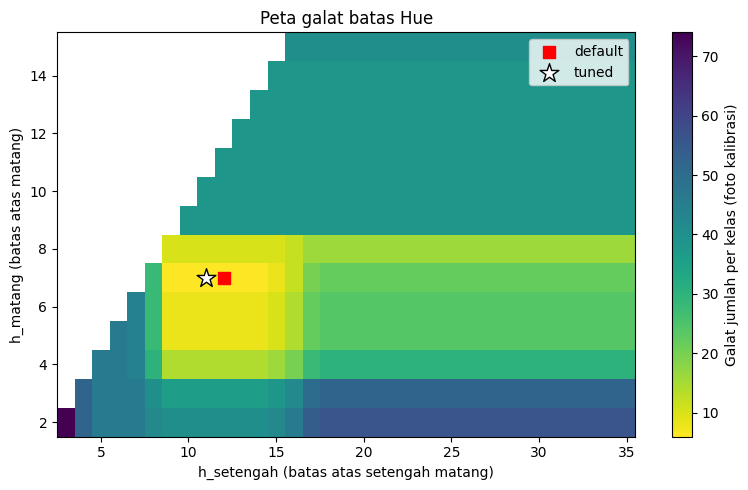


Konfigurasi final: TUNED (dituning pada data kalibrasi saja)


In [ ]:
HIMPUNAN = {"kalibrasi": KAL_ROWS, "uji": UJI_ROWS, "semua": DATA}

def tabel_banding(daftar_cfg):
    baris = []
    for nama, cfg in daftar_cfg.items():
        for himpunan, rows in HIMPUNAN.items():
            if not rows:
                continue
            s = hitung_skor(evaluasi(rows, cfg))
            baris.append(dict(konfigurasi=nama, himpunan=himpunan, n=s["n"],
                              acc_total=f"{s['acc_total']:.1f}%", acc_kelas=f"{s['acc_kelas']:.1f}%",
                              MAE_total=f"{s['MAE_total']:.2f}", MAE_kelas=f"{s['MAE_kelas']:.2f}"))
    return baris


print("Default vs tuned:")
tabel(tabel_banding({"DEFAULT": CFG_DEFAULT, "TUNED": CFG_TUNED}),
      ["konfigurasi", "himpunan", "n", "acc_total", "acc_kelas", "MAE_total", "MAE_kelas"])

# Peta galat batas Hue pada data kalibrasi
b_m = sorted({k[0] for k in PETA_HUE}); b_s = sorted({k[1] for k in PETA_HUE})
peta = np.full((len(b_m), len(b_s)), np.nan)
for (a, b), v in PETA_HUE.items():
    peta[b_m.index(a), b_s.index(b)] = v
plt.figure(figsize=(8, 5))
plt.imshow(peta, origin="lower", aspect="auto", cmap="viridis_r",
           extent=[b_s[0] - .5, b_s[-1] + .5, b_m[0] - .5, b_m[-1] + .5])
plt.colorbar(label="Galat jumlah per kelas (foto kalibrasi)")
plt.scatter(CFG_DEFAULT["h_setengah"], CFG_DEFAULT["h_matang"], c="red", marker="s", s=80, label="default")
plt.scatter(CFG_TUNED["h_setengah"], CFG_TUNED["h_matang"], c="white", edgecolors="k", marker="*", s=200, label="tuned")
plt.xlabel("h_setengah (batas atas setengah matang)"); plt.ylabel("h_matang (batas atas matang)")
plt.title("Peta galat batas Hue"); plt.legend(); plt.tight_layout(); plt.show()

# Konfigurasi final: tuned (ditentukan dari data kalibrasi saja)
CFG_FINAL, NAMA_FINAL = CFG_TUNED, "TUNED"
print(f"\nKonfigurasi final: {NAMA_FINAL} (dituning pada data kalibrasi saja)")

### 6.2 HSV vs BGR dan equalization channel V

**setiap skenario di-tuning dengan prosedur yang sama** pada data kalibrasi. Semua skenario berangkat dari `CFG_A` (parameter deteksi hasil tuning Tahap A), jadi baris **HSV tuned sama dengan konfigurasi final**. Kolom `ambang` membedakan ambang klasifikasi default dan ambang hasil tuning. Segmentasi buah tetap memakai HSV di semua skenario, jadi perbedaan hanya ada pada tahap klasifikasi (dan pada `eq_v`, yang juga memengaruhi segmentasi).

skenario   | ambang  | acc_total | acc_kelas_uji | acc_kelas_semua | MAE_kelas
-----------+---------+-----------+---------------+-----------------+----------
HSV        | default | 95.0%     | 25.0%         | 40.0%           | 0.60     
HSV        | tuned   | 95.0%     | 25.0%         | 40.0%           | 0.60     
BGR        | default | 95.0%     | 0.0%          | 0.0%            | 1.93     
BGR        | tuned   | 95.0%     | 0.0%          | 10.0%           | 1.37     
HSV + eq V | default | 95.0%     | 33.3%         | 45.0%           | 0.57     
HSV + eq V | tuned   | 95.0%     | 33.3%         | 45.0%           | 0.50     
BGR + eq V | default | 95.0%     | 0.0%          | 0.0%            | 1.93     
BGR + eq V | tuned   | 95.0%     | 25.0%         | 35.0%           | 0.87     


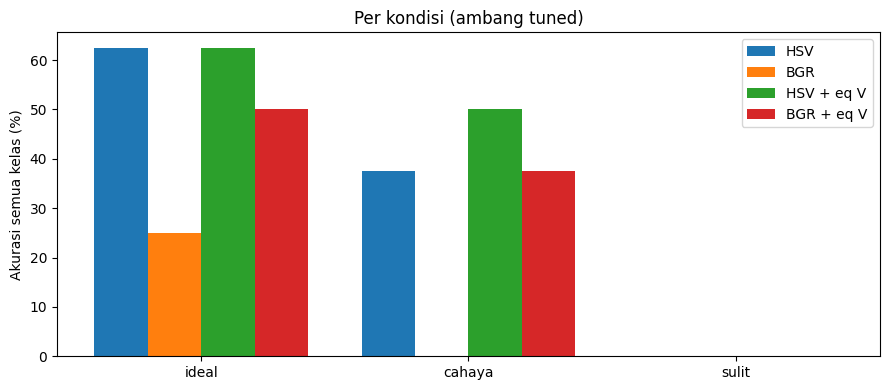

In [ ]:
SKENARIO = {"HSV": dict(ruang="hsv", eq_v=False), "BGR": dict(ruang="bgr", eq_v=False),
            "HSV + eq V": dict(ruang="hsv", eq_v=True), "BGR + eq V": dict(ruang="bgr", eq_v=True)}

baris, per_kondisi = [], {}
for nama, ubah in SKENARIO.items():
    cfg_d = buat_cfg(CFG_A, **ubah)                    # basis: deteksi hasil tuning Tahap A
    cfg_t = tuning_klasifikasi(KAL_ROWS, cfg_d)        # ambang klasifikasi dituning pada data kalibrasi
    for ambang, cfg in (("default", cfg_d), ("tuned", cfg_t)):
        hasil = evaluasi(DATA, cfg)
        uji = hitung_skor([h for h in hasil if h["kondisi"] not in KONDISI_KALIBRASI])
        semua = hitung_skor(hasil)
        baris.append(dict(skenario=nama, ambang=ambang, acc_total=f"{semua['acc_total']:.1f}%",
                          acc_kelas_uji=f"{uji['acc_kelas']:.1f}%", acc_kelas_semua=f"{semua['acc_kelas']:.1f}%",
                          MAE_kelas=f"{semua['MAE_kelas']:.2f}"))
        if ambang == "tuned":
            per_kondisi[nama] = [hitung_skor([h for h in hasil if h["kondisi"] == k])["acc_kelas"] for k in KOND]
tabel(baris, ["skenario", "ambang", "acc_total", "acc_kelas_uji", "acc_kelas_semua", "MAE_kelas"])

fig, ax = plt.subplots(figsize=(9, 4))
lebar = 0.8 / len(per_kondisi)
for i, (nama, v) in enumerate(per_kondisi.items()):
    ax.bar(np.arange(len(KOND)) + i * lebar, v, lebar, label=nama)
ax.set_xticks(np.arange(len(KOND)) + 0.4 - lebar / 2); ax.set_xticklabels(KOND)
ax.set_ylabel("Akurasi semua kelas (%)"); ax.set_title("Per kondisi (ambang tuned)"); ax.legend()
plt.tight_layout(); plt.show()

### 6.3 Sensitivitas parameter

Setiap parameter divariasikan satu per satu dari `CFG_DEFAULT` (nilai lain tetap default). Ini adalah analisis deskriptif pada seluruh data.

parameter   | nilai | default | acc_total | acc_kelas | MAE_total
------------+-------+---------+-----------+-----------+----------
blur_k      | 1     |         | 90.0      | 40.0      | 0.25     
blur_k      | 3     |         | 85.0      | 35.0      | 0.3      
blur_k      | 5     | *       | 85.0      | 35.0      | 0.35     
blur_k      | 9     |         | 85.0      | 35.0      | 0.3      
s_min       | 30    |         | 90.0      | 40.0      | 0.3      
s_min       | 40    |         | 85.0      | 35.0      | 0.35     
s_min       | 50    | *       | 85.0      | 35.0      | 0.35     
s_min       | 60    |         | 90.0      | 30.0      | 0.3      
s_min       | 70    |         | 85.0      | 30.0      | 0.4      
v_rel       | 0.6   |         | 55.0      | 25.0      | 0.7      
v_rel       | 0.7   |         | 95.0      | 40.0      | 0.2      
v_rel       | 0.75  |         | 95.0      | 45.0      | 0.2      
v_rel       | 0.8   |         | 95.0      | 40.0      | 0.2      
v_rel     

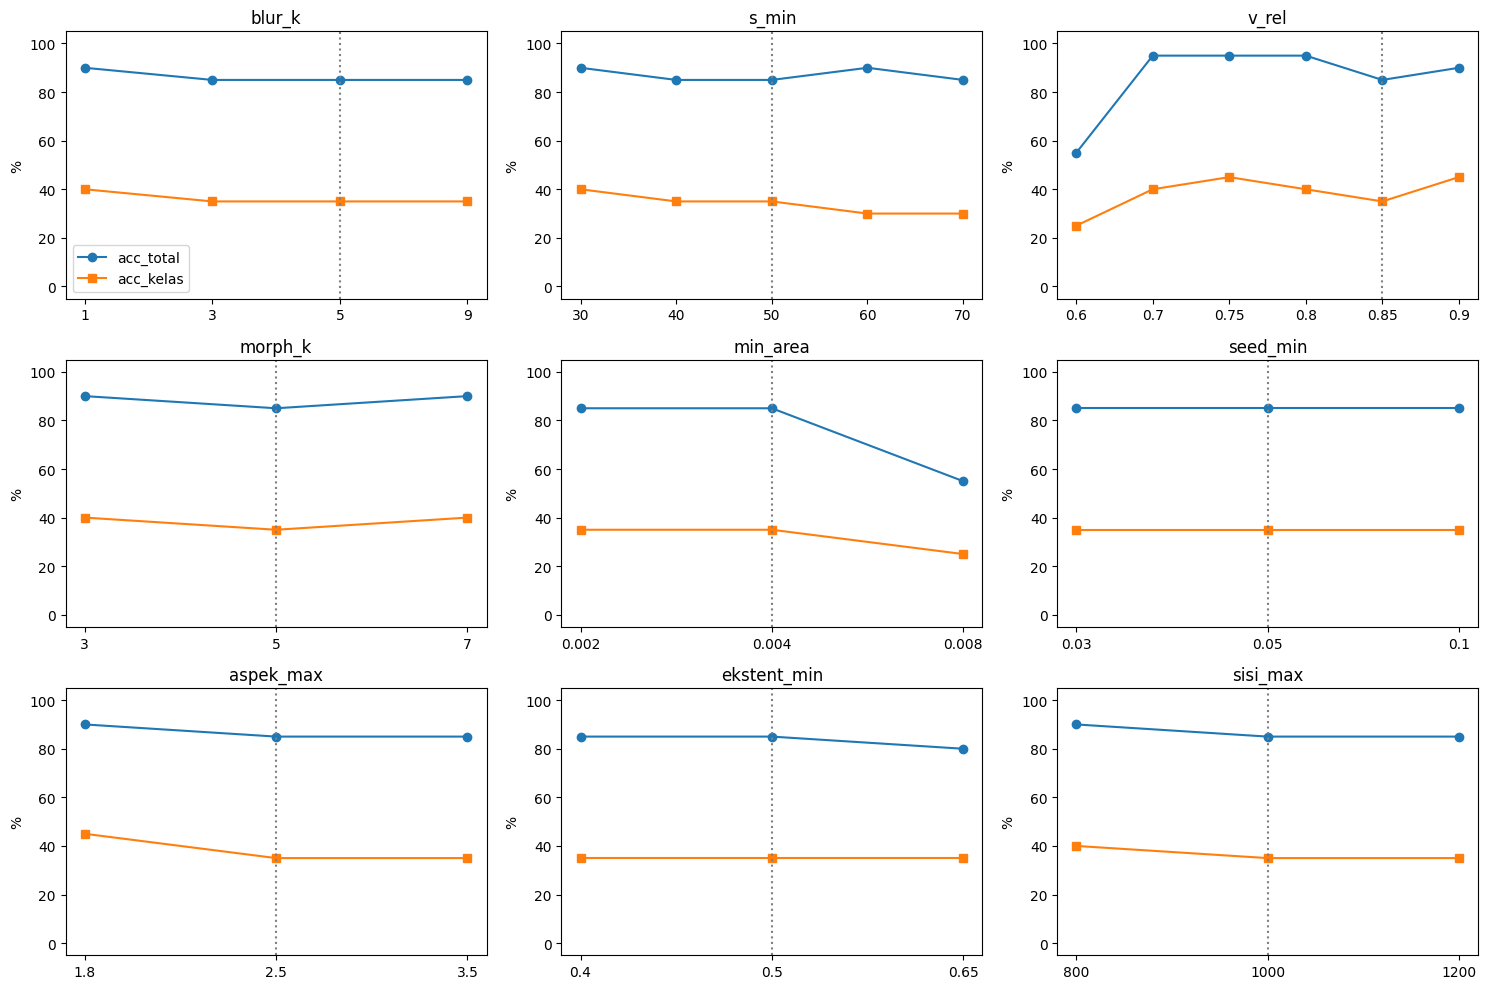

In [ ]:
SWEEP = {
    "blur_k": [1, 3, 5, 9],
    "s_min": [30, 40, 50, 60, 70],
    "v_rel": [0.6, 0.7, 0.75, 0.8, 0.85, 0.9],
    "morph_k": [3, 5, 7],
    "min_area": [0.002, 0.004, 0.008],
    "seed_min": [0.03, 0.05, 0.10],
    "aspek_max": [1.8, 2.5, 3.5],
    "ekstent_min": [0.4, 0.5, 0.65],
    "sisi_max": [800, 1000, 1200],
}

baris = []
for param, nilai_list in SWEEP.items():
    for nilai in nilai_list:
        s = hitung_skor(evaluasi(DATA, buat_cfg(CFG_DEFAULT, **{param: nilai})))
        baris.append(dict(parameter=param, nilai=nilai, default="*" if nilai == CFG_DEFAULT[param] else "",
                          acc_total=round(s["acc_total"], 1), acc_kelas=round(s["acc_kelas"], 1),
                          MAE_total=round(s["MAE_total"], 2)))
tabel(baris, ["parameter", "nilai", "default", "acc_total", "acc_kelas", "MAE_total"])

fig, ax = plt.subplots(3, 3, figsize=(15, 10))
for a, (param, nilai_list) in zip(ax.ravel(), SWEEP.items()):
    b = [x for x in baris if x["parameter"] == param]
    pos = range(len(b))
    a.plot(pos, [x["acc_total"] for x in b], "o-", label="acc_total")
    a.plot(pos, [x["acc_kelas"] for x in b], "s-", label="acc_kelas")
    a.set_xticks(list(pos)); a.set_xticklabels([x["nilai"] for x in b])
    a.axvline(nilai_list.index(CFG_DEFAULT[param]), color="gray", ls=":")
    a.set_title(param); a.set_ylim(-5, 105); a.set_ylabel("%")
ax[0, 0].legend()
plt.tight_layout(); plt.show()

### 6.4 Hasil akhir dengan konfigurasi final

Evaluasi lengkap dengan `CFG_FINAL` (= `CFG_TUNED`), penyimpanan citra hasil ke `output/`, dan tabel hasil ke `output/hasil_evaluasi.csv`.

In [ ]:
HASIL_FINAL = evaluasi(DATA, CFG_FINAL)

print(f"Konfigurasi final: {NAMA_FINAL}")
tabel(HASIL_FINAL, ["file", "kondisi", "gt", "pred", "err_total", "benar_total", "benar_kelas"])
print("\nAkurasi per kondisi:")
tabel(tabel_kondisi(HASIL_FINAL), ["kondisi", "n", "acc_total", "acc_semua_kelas", "MAE_total", "MAE_kelas"])
print("\nMetrik per kelas (batas atas):")
tabel(metrik_kelas(HASIL_FINAL), ["kelas", "GT", "pred", "precision", "recall", "MAE"])

for r in DATA:
    img = muat_citra(r["path"], CFG_FINAL["sisi_max"])
    cv2.imwrite(os.path.join(OUTPUT_DIR, f"hasil_{r['file']}"), gambar_hasil(img, jalankan_pipeline(img, CFG_FINAL)))

kolom = ["file", "kondisi", "gt", "pred", "err_total", "err_kls", "benar_total", "benar_kelas"]
with open(os.path.join(OUTPUT_DIR, "hasil_evaluasi.csv"), "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=kolom)
    w.writeheader()
    w.writerows([{k: h[k] for k in kolom} for h in HASIL_FINAL])
print(f"\n{len(DATA)} citra hasil dan hasil_evaluasi.csv disimpan di {OUTPUT_DIR}/")

Konfigurasi final: TUNED
file           | kondisi | gt        | pred      | err_total | benar_total | benar_kelas
---------------+---------+-----------+-----------+-----------+-------------+------------
ideal_02.jpg   | ideal   | 7 (1/3/3) | 7 (1/4/2) | 0         | 1           | 0          
ideal_03.jpg   | ideal   | 6 (1/2/3) | 6 (1/3/2) | 0         | 1           | 0          
ideal_07.jpg   | ideal   | 8 (1/3/4) | 8 (1/4/3) | 0         | 1           | 0          
ideal_01.jpg   | ideal   | 8 (1/3/4) | 8 (1/3/4) | 0         | 1           | 1          
ideal_04.jpg   | ideal   | 5 (1/2/2) | 5 (1/2/2) | 0         | 1           | 1          
ideal_05.jpg   | ideal   | 4 (1/2/1) | 4 (1/2/1) | 0         | 1           | 1          
ideal_06.jpg   | ideal   | 3 (1/1/1) | 3 (1/1/1) | 0         | 1           | 1          
ideal_08.jpg   | ideal   | 6 (1/3/2) | 6 (1/3/2) | 0         | 1           | 1          
lampu_01.jpg   | cahaya  | 4 (0/2/2) | 4 (0/2/2) | 0         | 1           | 1       

## 7. Analisis kegagalan

Tiga foto dengan galat terbesar dari konfigurasi final ditampilkan dengan Hue, Saturation, dan Value median tiap buah (`H S V`) serta mask-nya. Teks diagnosis disusun otomatis dari angka pada foto itu: jenis galat (deteksi atau klasifikasi), bukti numerik, dan penyebab yang paling mungkin.

[ideal_02.jpg] kondisi ideal
  - Deteksi benar (jumlah total sama), galat hanya pada klasifikasi kelas.
  - Selisih per kelas: setengah_matang: GT 3 -> pred 4; matang: GT 3 -> pred 2
  - Median Hue per buah: [4.0, 5.0, 8.0, 8.0, 9.0, 9.0, 16.0] | batas: matang <= 7, setengah <= 11
  - 4 dari 7 buah berada dalam 2 unit dari batas kelas, jadi pergeseran warna kecil sudah cukup membalik kelasnya.
[jendela_02.jpg] kondisi cahaya
  - Deteksi benar (jumlah total sama), galat hanya pada klasifikasi kelas.
  - Selisih per kelas: mentah: GT 1 -> pred 0; setengah_matang: GT 1 -> pred 3; matang: GT 2 -> pred 1
  - Median Hue per buah: [5.0, 8.0, 9.0, 11.0] | batas: matang <= 7, setengah <= 11
  - 3 dari 4 buah berada dalam 2 unit dari batas kelas, jadi pergeseran warna kecil sudah cukup membalik kelasnya.
[sulit_01.jpg] kondisi sulit
  - Galat deteksi: terdeteksi 1 buah, GT 5 (selisih -4). Periksa mask: buah menyatu atau objek non-buah ikut terdeteksi.
  - Selisih per kelas: setengah_matang: GT 3

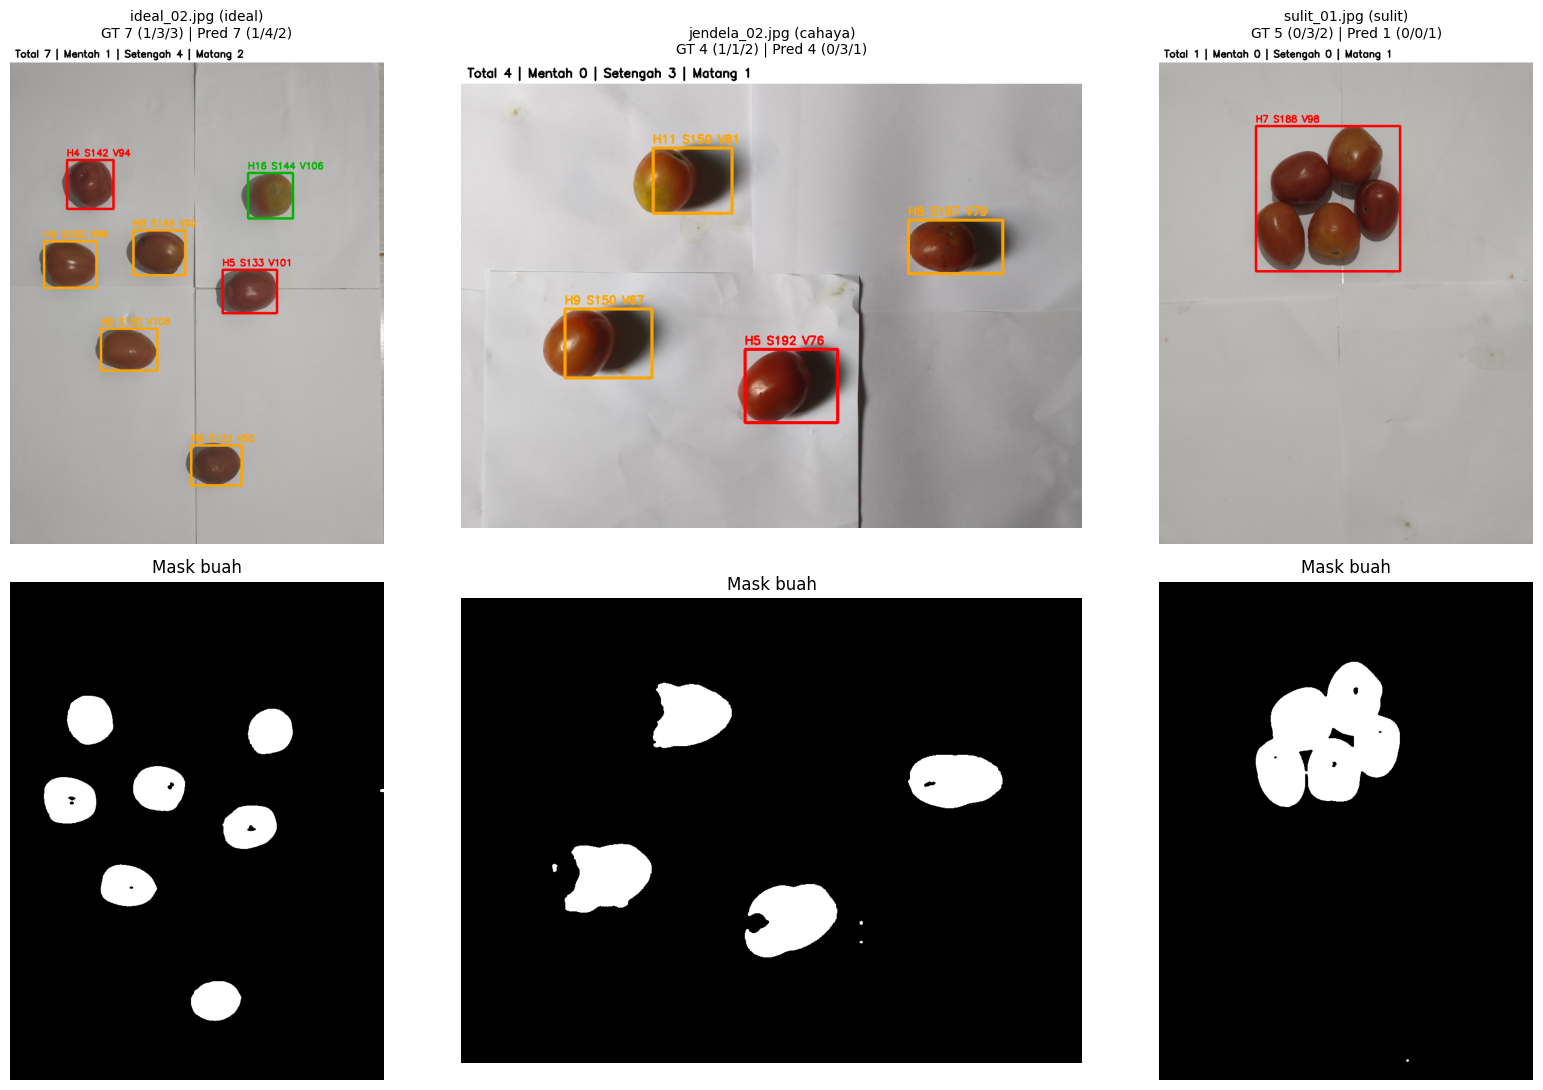


Bias rata-rata per kondisi (prediksi - GT, jumlah per foto):
kondisi | mentah | setengah_matang | matang
--------+--------+-----------------+-------
ideal   | +0.00  | +0.38           | -0.38 
cahaya  | -0.38  | +0.50           | -0.12 
sulit   | +0.00  | -1.50           | +0.50 


In [ ]:
def diagnosis(h, cfg):
    """jenis galat, selisih per kelas, median Hue buah vs batas kelas."""
    p = jalankan_pipeline(muat_citra(h["path"], cfg["sisi_max"]), cfg)
    selisih = h["total_pred"] - h["total_gt"]
    teks = []

    if selisih != 0:
        teks.append(f"Galat deteksi: terdeteksi {h['total_pred']} buah, GT {h['total_gt']} (selisih {selisih:+d}). "
                    "Periksa mask: buah menyatu atau objek non-buah ikut terdeteksi.")
    else:
        teks.append("Deteksi benar (jumlah total sama), galat hanya pada klasifikasi kelas.")

    beda = [f"{k}: GT {h['gk'][k]} -> pred {h['pk'][k]}" for k in KELAS if h["pk"][k] != h["gk"][k]]
    if beda:
        teks.append("Selisih per kelas: " + "; ".join(beda))

    if cfg["ruang"] == "hsv" and p["hasil"]:
        hue = sorted(round(b["h_med"] - GESER, 1) for b in p["hasil"])
        batas = [cfg["h_matang"] + 0.5, cfg["h_setengah"] + 0.5]
        dekat = [x for x in hue if min(abs(x - b) for b in batas) <= 2]
        teks.append(f"Median Hue per buah: {hue} | batas: matang <= {cfg['h_matang']}, setengah <= {cfg['h_setengah']}")
        if dekat:
            teks.append(f"{len(dekat)} dari {len(hue)} buah berada dalam 2 unit dari batas kelas, "
                        "jadi pergeseran warna kecil sudah cukup membalik kelasnya.")
    return p, teks


# Satu contoh gagal terburuk per kondisi
GAGAL = []
for k in KOND:
    sub = [h for h in HASIL_FINAL if h["kondisi"] == k and h["err_kls"] > 0]
    if sub:
        GAGAL.append(max(sub, key=lambda h: (h["err_kls"], h["err_total"])))

if not GAGAL:
    print("Tidak ada foto yang gagal pada konfigurasi final.")
else:
    fig, ax = plt.subplots(2, len(GAGAL), figsize=(6 * len(GAGAL), 11), squeeze=False)
    for j, h in enumerate(GAGAL):
        p, teks = diagnosis(h, CFG_FINAL)
        img = muat_citra(h["path"], CFG_FINAL["sisi_max"])
        ax[0, j].imshow(rgb(gambar_hasil(img, p, detail=True)))
        ax[0, j].set_title(f"{h['file']} ({h['kondisi']})\nGT {h['gt']} | Pred {h['pred']}", fontsize=10)
        ax[1, j].imshow(p["mask"], cmap="gray"); ax[1, j].set_title("Mask buah")
        ax[0, j].axis("off"); ax[1, j].axis("off")
        print(f"[{h['file']}] kondisi {h['kondisi']}")
        for t in teks:
            print("  -", t)
    plt.tight_layout(); plt.show()

print("\nBias rata-rata per kondisi (prediksi - GT, jumlah per foto):")
bias = []
for k in KOND:
    sub = [h for h in HASIL_FINAL if h["kondisi"] == k]
    bias.append(dict(kondisi=k, **{kls: f"{np.mean([h['pk'][kls] - h['gk'][kls] for h in sub]):+.2f}" for kls in KELAS}))
tabel(bias, ["kondisi"] + KELAS)

### Pembahasan

| Foto | Jenis galat | Bukti | Penyebab | Usulan perbaikan |
|---|---|---|---|---|
| ideal_02 | klasifikasi | Total 7 benar; setengah matang +1, matang -1 (pred 1/4/2 vs GT 1/3/3) | Hue matang dan setengah matang saling berdekatan (p90 matang 8, p10 setengah matang 8), sehingga buah di batas kelas mudah tertukar | Fitur kedua (kecerahan V relatif) atau anotasi kelas per buah |
| jendela_02 | klasifikasi | Total 4 benar; mentah 1 -> 0, setengah matang 1 -> 3, matang 2 -> 1 | Cahaya jendela menggeser Hue buah ke dekat batas kelas; ambang dikalibrasi pada foto ideal | Kalibrasi ambang per kondisi cahaya atau normalisasi warna latar |
| sulit_01 | deteksi | 1 buah terdeteksi, GT 5 | Buah menumpuk rapat menjadi satu kontur tanpa celah, sehingga erosi 3x3 tidak bisa memisahkannya | Foto dengan sedikit celah antarbuah, atau pemisahan berbasis jarak (di luar Prak 1-5) |

Galat deteksi hanya muncul pada kondisi sulit (buah menumpuk). Pada kondisi ideal dan cahaya jumlah total buah selalu benar, sehingga galat utama ada di **klasifikasi**: rentang Hue antar kelas sempit dan bergeser ketika cahaya berubah. Tabel bias menunjukkan arah pergeseran per kondisi.

## 8. Kesimpulan

In [ ]:
s_def = hitung_skor(evaluasi(DATA, CFG_DEFAULT))
s_fin = hitung_skor(HASIL_FINAL)
s_uji_def = hitung_skor(evaluasi(UJI_ROWS, CFG_DEFAULT)) if UJI_ROWS else None
s_uji_fin = hitung_skor([h for h in HASIL_FINAL if h["kondisi"] not in KONDISI_KALIBRASI]) if UJI_ROWS else None

print(f"Dataset: {len(DATA)} foto, {sum(r['total'] for r in DATA)} buah, kondisi: {', '.join(KOND)}")
print(f"Konfigurasi final: {NAMA_FINAL}")
print(f"Default : acc_total {s_def['acc_total']:.1f}% | acc_semua_kelas {s_def['acc_kelas']:.1f}% | MAE_kelas {s_def['MAE_kelas']:.2f}")
print(f"Final   : acc_total {s_fin['acc_total']:.1f}% | acc_semua_kelas {s_fin['acc_kelas']:.1f}% | MAE_kelas {s_fin['MAE_kelas']:.2f}")
if s_uji_def:
    print(f"Data uji (kondisi selain kalibrasi): default {s_uji_def['acc_kelas']:.1f}% -> final {s_uji_fin['acc_kelas']:.1f}% (semua kelas)")
for k in KOND:
    s = hitung_skor([h for h in HASIL_FINAL if h["kondisi"] == k])
    print(f"  {k:8s}: acc_total {s['acc_total']:.1f}% | acc_semua_kelas {s['acc_kelas']:.1f}%")

Dataset: 20 foto, 100 buah, kondisi: ideal, cahaya, sulit
Konfigurasi final: TUNED
Default : acc_total 85.0% | acc_semua_kelas 35.0% | MAE_kelas 0.62
Final   : acc_total 95.0% | acc_semua_kelas 40.0% | MAE_kelas 0.60
Data uji (kondisi selain kalibrasi): default 16.7% -> final 25.0% (semua kelas)
  ideal   : acc_total 100.0% | acc_semua_kelas 62.5%
  cahaya  : acc_total 100.0% | acc_semua_kelas 37.5%
  sulit   : acc_total 75.0% | acc_semua_kelas 0.0%


**Kesimpulan metode.**
- Pipeline klasik (blur -> HSV -> mask `inRange` -> kontur -> klasifikasi rentang Hue), setiap buah diberi bounding box, diklasifikasikan ke tiga tingkat kematangan, dan histogram Hue per kelas ditampilkan sebagai dasar rentang.
- Hasil final (`CFG_TUNED`) pada 20 foto: akurasi jumlah total 95,0%, akurasi semua kelas 40,0%, MAE per kelas 0,60. Per kondisi (semua kelas): ideal 62,5%, cahaya 37,5%, sulit 0%. Pada data uji (selain ideal), tuning menaikkan akurasi semua kelas dari 16,7% (default) ke 25,0%.
- Deteksi (jumlah buah) jauh lebih stabil daripada klasifikasi kelas. Kesalahan terbesar ada pada penentuan kelas ketika cahaya atau latar berubah, karena rentang Hue antar kelas sempit (median Hue mentah 17, setengah matang 9, matang 4).

**Keterbatasan.**
- Dataset kecil (20 foto) dan buah yang sama dipakai berulang, sehingga sampel efektif jauh lebih kecil daripada jumlah buah.
- Definisi "setengah matang" subjektif dan kelasnya berupa warna campuran, padahal fitur yang dipakai satu nilai median Hue.
- Ambang dikalibrasi pada foto ideal; kondisi cahaya lain bisa menggeser Hue. Buah yang menumpuk rapat belum bisa dipisahkan.

### 8.2 Demo pada foto baru

Isi `DEMO_PATH` dengan path foto baru (relatif), lalu jalankan sel di bawah ini!

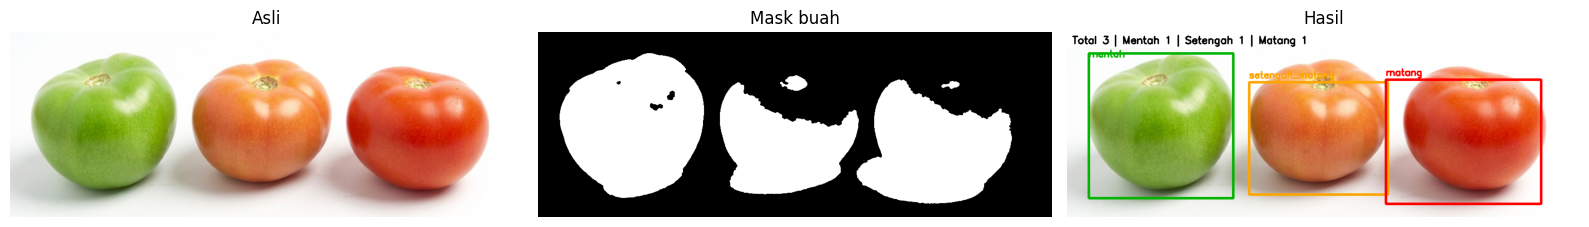

Jumlah per kelas: {'mentah': 1, 'setengah_matang': 1, 'matang': 1} | total: 3


In [ ]:
DEMO_PATH = "/content/test_viskom.jpeg"

def demo(path, cfg=None, v_rel=None):
    """Jalankan pipeline final pada satu foto baru dan tampilkan hasil antaranya.

    v_rel: opsional, menimpa batas V relatif (default dari CFG_FINAL) hanya untuk demo ini.
    """
    cfg = dict(cfg or CFG_FINAL)
    if v_rel is not None:
        cfg["v_rel"] = v_rel
    img = muat_citra(path, cfg["sisi_max"])
    p = jalankan_pipeline(img, cfg)
    fig, ax = plt.subplots(1, 3, figsize=(16, 5))
    for a, (judul, im, cmap) in zip(ax, [("Asli", rgb(img), None), ("Mask buah", p["mask"], "gray"),
                                         ("Hasil", rgb(gambar_hasil(img, p)), None)]):
        a.imshow(im, cmap=cmap); a.set_title(judul); a.axis("off")
    plt.tight_layout(); plt.show()
    print("Jumlah per kelas:", p["hitung"], "| total:", p["total"])
    return p


if DEMO_PATH:
    demo(DEMO_PATH, v_rel=1.0)
else:
    print("Isi path untuk menjalankan demo.")

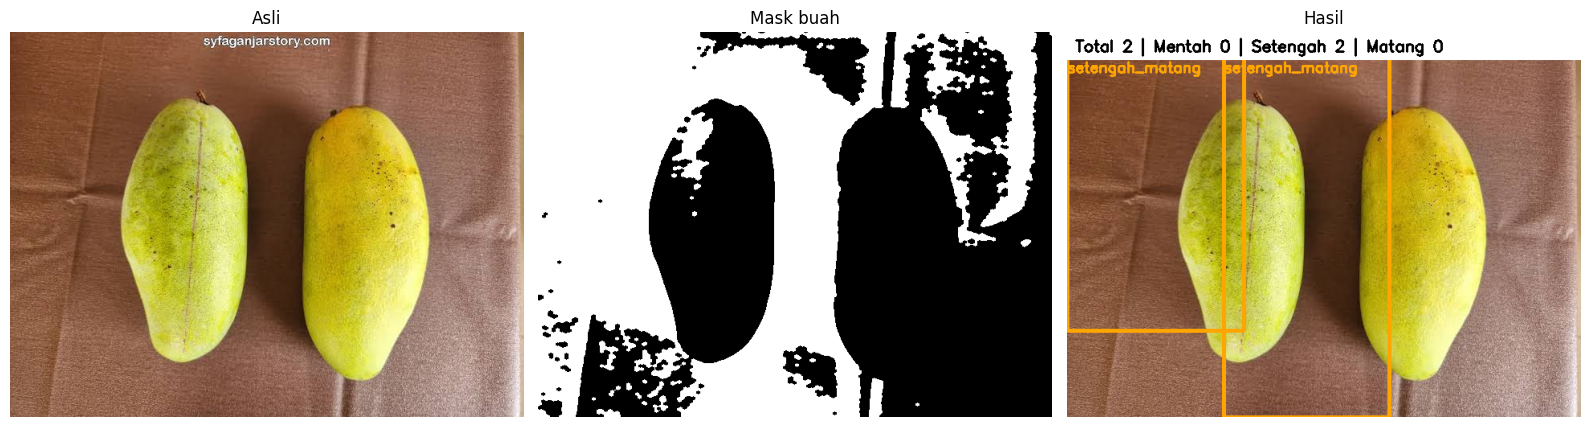

Jumlah per kelas: {'mentah': 0, 'setengah_matang': 2, 'matang': 0} | total: 2


In [ ]:
DEMO_PATH = "/content/images (4).jpg"

def demo(path, cfg=None, v_rel=None):
    """Jalankan pipeline final pada satu foto baru dan tampilkan hasil antaranya.

    v_rel: opsional, menimpa batas V relatif (default dari CFG_FINAL) hanya untuk demo ini.
    """
    cfg = dict(cfg or CFG_FINAL)
    if v_rel is not None:
        cfg["v_rel"] = v_rel
    img = muat_citra(path, cfg["sisi_max"])
    p = jalankan_pipeline(img, cfg)
    fig, ax = plt.subplots(1, 3, figsize=(16, 5))
    for a, (judul, im, cmap) in zip(ax, [("Asli", rgb(img), None), ("Mask buah", p["mask"], "gray"),
                                         ("Hasil", rgb(gambar_hasil(img, p)), None)]):
        a.imshow(im, cmap=cmap); a.set_title(judul); a.axis("off")
    plt.tight_layout(); plt.show()
    print("Jumlah per kelas:", p["hitung"], "| total:", p["total"])
    return p


if DEMO_PATH:
    demo(DEMO_PATH, v_rel=1.0)
else:
    print("Isi path untuk menjalankan demo.")